# 2. 히스토그램 (Histogram)

히스토그램은 **픽셀 값을 종류별로 세어 놓은 그래프**다. 레나 영상의 밝기 분포를 확인하고, 전체 평활화와 CLAHE로 대비가 어떻게 변하는지 비교한다. 실습은 8비트 `uint8` 영상을 사용한다.

## 2.1 히스토그램의 개념

### 밝기별로 픽셀을 분류한 개수표

- 픽셀을 밝기별 상자에 담고, 각 상자에 몇 개가 들어 있는지 센다고 생각하면 된다.
- 가로축은 **픽셀 값**이고, 세로축은 **해당 값을 가진 픽셀 개수**다.
- Gray 영상에서 왼쪽은 어두운 값, 오른쪽은 밝은 값이다.
- 가로축은 픽셀의 위치도, DFT의 주파수도 아니다.

예를 들어 픽셀 값이 `[0, 0, 128, 255]`라면 다음과 같다.

| 픽셀 값 | 개수 | 비율 |
| :---: | :---: | :---: |
| 0 | 2 | 0.50 |
| 128 | 1 | 0.25 |
| 255 | 1 | 0.25 |
| 나머지 | 0 | 0 |

$$
h(k)=\sum_{y=0}^{H-1}\sum_{x=0}^{W-1}\mathbf{1}[I(y,x)=k]
$$

- $h(k)$: 밝기가 $k$인 픽셀 개수
- $H,W$: 영상의 높이와 너비
- $\mathbf{1}[\cdot]$: 조건이 맞으면 1, 아니면 0

모든 개수를 더하면 전체 픽셀 수 $N=HW$가 된다. 비율로 바꾸면 서로 크기가 다른 영상도 분포를 비교하기 쉽다.

$$
\sum_{k=0}^{255}h(k)=N,\qquad p(k)=\frac{h(k)}{N},\qquad \sum_{k=0}^{255}p(k)=1
$$

### 그래프를 읽는 방법

| 분포 모습 | 해석의 단서 |
| :---: | :---: |
| 왼쪽에 많이 모임 | 어두운 픽셀이 많음 |
| 오른쪽에 많이 모임 | 밝은 픽셀이 많음 |
| 좁은 범위에 모임 | 전체 밝기 변화가 작을 가능성 |
| 넓게 퍼짐 | 다양한 밝기 값이 존재함 |

> [!warning] 그래프만으로 영상 품질을 판단하지 않기
> 밤 사진은 어두운 값이 많아도 자연스럽다. 넓은 분포가 항상 좋은 사진을 뜻하지 않는다. 히스토그램은 픽셀의 위치를 저장하지 않으므로 서로 다른 사진이 같은 히스토그램을 가질 수 있다.

값 0: 개수 2, 비율 0.50
값 128: 개수 1, 비율 0.25
값 255: 개수 1, 비율 0.25
OpenCV: 5.0.0


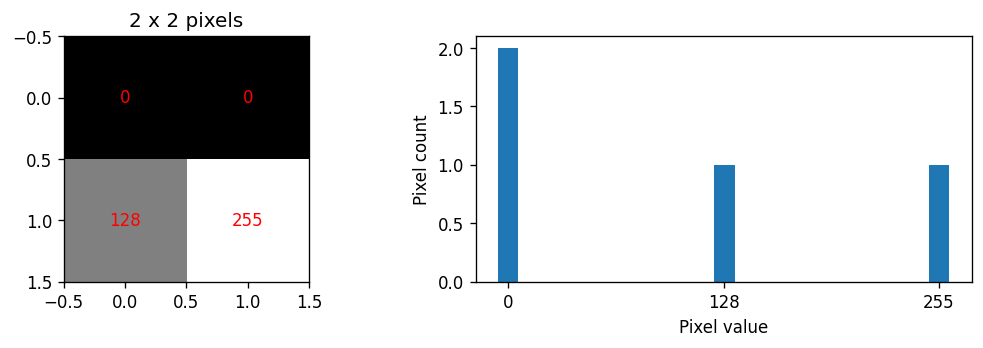

In [1]:
# 셀 1: 히스토그램의 기본 집계
# 2×2 예제에서 값별 개수와 비율을 직접 확인한다.

# Path는 운영체제에 맞게 파일 경로를 조합하는 데 사용한다.
from pathlib import Path
# OpenCV는 영상 처리, NumPy는 배열 계산, Matplotlib은 결과 시각화에 사용한다.
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 현재 작업 폴더를 기준으로 assets를 찾는다. 노트북은 각 장의 폴더에서 실행한다.
ROOT = Path.cwd()  # 노트북과 assets 폴더가 있는 위치
path = ROOT / 'assets' / 'Lenna.png'
if not path.exists():
    raise FileNotFoundError('assets/Lenna.png를 확인하세요.')
# 파일을 바이트 배열로 읽어 디코딩한다. IMREAD_COLOR의 결과는 BGR 순서다.
img = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)
if img is None:
    raise ValueError('이미지 디코딩 실패')
# B·G·R을 밝기 가중합으로 바꾸어 단일 채널 영상으로 만든다.
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 8비트 밝기값 0~255를 256개 구간으로 세어 1차원 배열로 반환한다.
def hist(a):
    # channels는 집계할 채널, histSize는 구간 수, ranges의 끝값 256은 포함하지 않는다.
    return cv2.calcHist([a], [0], None, [256], [0, 256]).ravel()

sample = np.array([[0, 0], [128, 255]], dtype=np.uint8)
h = hist(sample)
for k in [0, 128, 255]:
    print(f'값 {k}: 개수 {int(h[k])}, 비율 {h[k]/sample.size:.2f}')
assert h.sum() == sample.size
print('OpenCV:', cv2.__version__)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].imshow(sample, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('2 x 2 pixels')
for y in range(2):
    for x in range(2):
        axes[0].text(x,y,str(sample[y,x]),ha='center',va='center',color='red')
axes[1].bar([0,128,255], h[[0,128,255]], width=12)
axes[1].set(xlabel='Pixel value', ylabel='Pixel count', xticks=[0,128,255])
fig.tight_layout()
plt.show()

## 2.2 그레이스케일 및 컬러 히스토그램

### 그레이스케일 히스토그램



| 인수 | 의미 |
| :---: | :---: |
| `[gray]` | 계산할 영상 |
| `[0]` | 사용할 채널 번호 |
| `None` | 전체 영역 집계 |
| `[256]` | 값을 담는 구간(bin) 256개 |
| `[0, 256]` | 0 이상 256 미만, 즉 0~255 포함 |

- 256개 bin을 사용하면 정수 값 하나당 상자 하나다.
- 16개 bin이라면 0~15, 16~31처럼 여러 값을 묶는다.
- `calcHist()`의 단일 채널 결과 모양은 `(256, 1)`이다. `.ravel()`로 1차원으로 펼칠 수 있다.
- 관심 영역만 세려면 같은 높이·너비의 8비트 마스크를 사용한다. 마스크가 0이 아닌 위치만 집계된다.

영상 크기: (250, 250) 픽셀 수: 62500
히스토그램 합: 62500


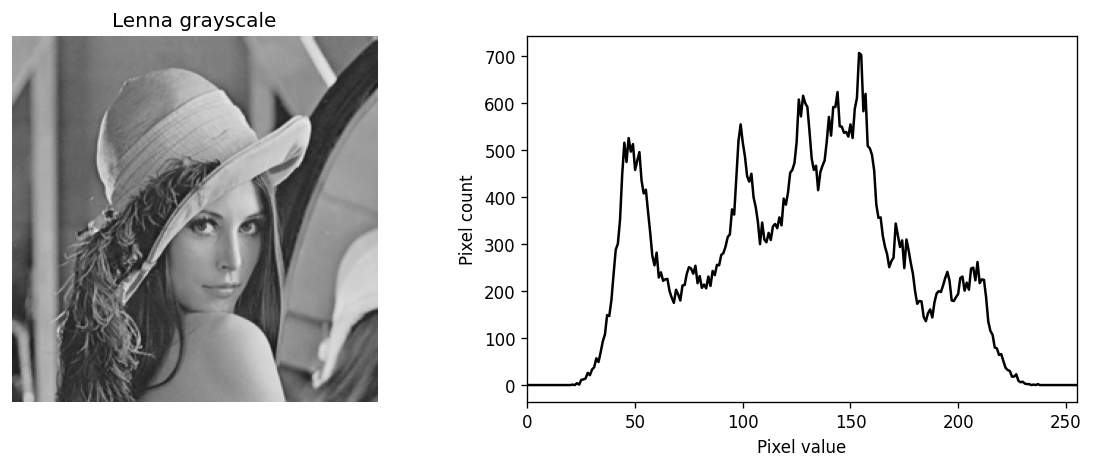

In [2]:
# 셀 2: 레나의 그레이스케일 히스토그램
# 히스토그램의 합이 전체 픽셀 수와 같고 NumPy 집계와 일치하는지 확인한다.

h_gray = hist(gray)
assert h_gray.sum() == gray.size
assert np.array_equal(h_gray, np.bincount(gray.ravel(), minlength=256))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(gray, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Lenna grayscale')
axes[0].axis('off')
axes[1].plot(h_gray, color='black')
axes[1].set(xlim=(0,255), xlabel='Pixel value', ylabel='Pixel count')
fig.tight_layout()
plt.show()
print('영상 크기:', gray.shape, '픽셀 수:', gray.size)
print('히스토그램 합:', int(h_gray.sum()))

### 컬러 히스토그램



- OpenCV의 BGR 영상은 0번이 B, 1번이 G, 2번이 R이다.
- 채널별 그래프는 해당 색 성분의 **숫자 분포**다. 빨간 선 자체가 빨간 물체의 개수는 아니다.
- 각각의 채널 히스토그램 합은 $N$이다. 세 채널의 개수를 모두 합치면 $3N$이다.
- Gray 히스토그램은 B·G·R 히스토그램을 단순히 더한 결과가 아니다.
- 채널별 1차원 히스토그램만으로는 같은 픽셀에서 세 성분이 어떻게 조합되는지 알 수 없다.

blue 픽셀 수: 62500
green 픽셀 수: 62500
red 픽셀 수: 62500


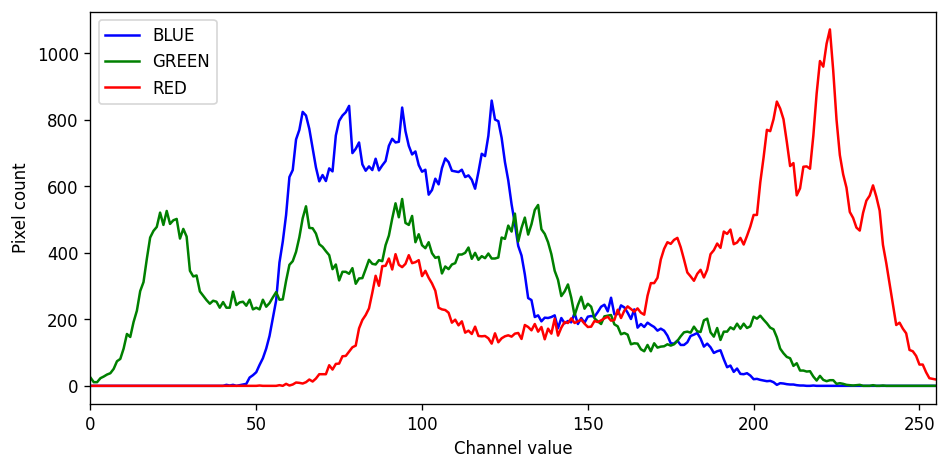

In [3]:
# 셀 3: B·G·R 채널별 히스토그램
# 세 채널을 따로 집계한다. 각 그래프는 해당 성분의 값 분포를 나타낸다.

fig, ax = plt.subplots(figsize=(8, 4))
for channel, color in enumerate(['blue', 'green', 'red']):
    # channels는 집계할 채널, histSize는 구간 수, ranges의 끝값 256은 포함하지 않는다.
    h = cv2.calcHist([img], [channel], None, [256], [0, 256]).ravel()
    assert h.sum() == gray.size
    ax.plot(h, color=color, label=color.upper())
    print(color, '픽셀 수:', int(h.sum()))
ax.set(xlim=(0,255), xlabel='Channel value', ylabel='Pixel count')
ax.legend()
fig.tight_layout()
plt.show()

### 관심 영역만 집계하기

- 마스크는 영상에 붙이는 선택 표시와 같다. **0이 아닌 위치의 픽셀만 센다.**
- 전체 영상과 영역의 크기가 다르므로 개수 대신 비율로 비교한다.
- 선택 영역은 얼굴 주변의 직사각형이며, 얼굴을 자동 검출한 결과가 아니다.

선택한 픽셀 수: 8925


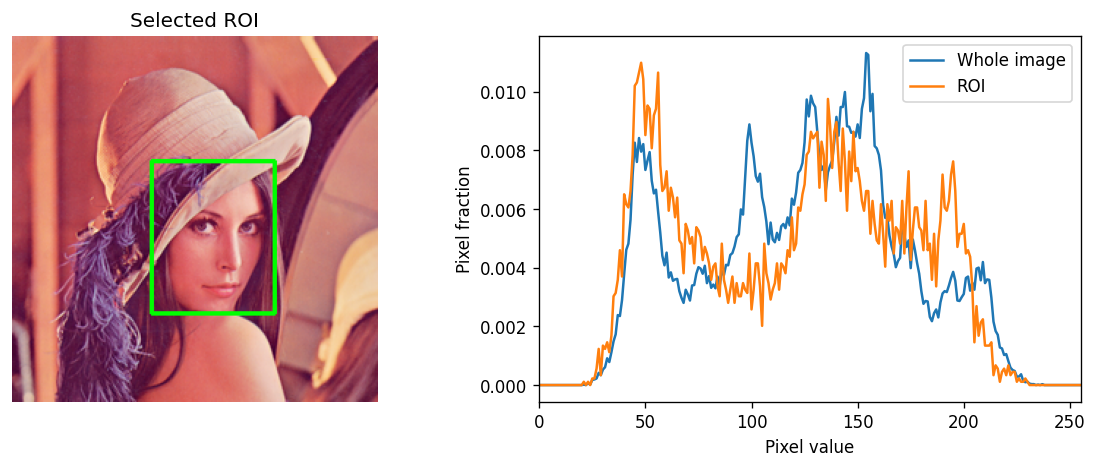

In [4]:
# 셀 4: 관심 영역의 히스토그램
# 마스크가 0이 아닌 위치만 세고, 크기가 다른 영역은 비율로 비교한다.

mask = np.zeros_like(gray)
mask[85:190, 95:180] = 255
# 8비트 마스크에서 0이 아닌 위치만 집계한다. 범위의 위쪽 끝 256은 제외된다.
h_roi = cv2.calcHist([gray], [0], mask, [256], [0,256]).ravel()
assert h_roi.sum() == np.count_nonzero(mask)
marked = img.copy()
# 오른쪽 아래 좌표도 포함해 그린다. 폭·높이에서 1을 빼면 지정한 픽셀 범위와 맞는다.
cv2.rectangle(marked, (95,85), (179,189), (0,255,0), 2)
fig, axes = plt.subplots(1, 2, figsize=(10,4))
axes[0].imshow(cv2.cvtColor(marked, cv2.COLOR_BGR2RGB))
axes[0].axis('off')
axes[0].set_title('Selected ROI')
axes[1].plot(h_gray/gray.size, label='Whole image')
axes[1].plot(h_roi/h_roi.sum(), label='ROI')
axes[1].set(xlim=(0,255), xlabel='Pixel value', ylabel='Pixel fraction')
axes[1].legend()
fig.tight_layout()
plt.show()
print('선택한 픽셀 수:', int(h_roi.sum()))

## 2.3 히스토그램 평활화

### 밝기 값을 다시 배정하기

- 픽셀 위치는 그대로 두고 밝기 값을 바꾼다.
- 전체 영상의 밝기 분포를 바탕으로 변환표를 만든다.
- 좁은 밝기 범위에 모인 영상에서 대비를 높이는 데 도움이 될 수 있다.
- **평활화(equalization)**는 평균·가우시안 필터의 **평활화(smoothing)**와 다르다. 여기서는 흐리게 만드는 주변 픽셀 평균을 계산하지 않는다.

### 누적 분포 함수(CDF)

밝기 $k$ 이하의 픽셀이 전체의 얼마나 되는지 누적해서 센다.

$$
C(k)=\sum_{j=0}^{k}p(j)
$$

처음 예제에서 $C(0)=0.5$, $C(128)=0.75$, $C(255)=1$이다.

최초의 0이 아닌 누적 비율을 $C_{\min}$이라 하면 다음 식으로 변환 원리를 설명할 수 있다.

$$
T(k)=\operatorname{round}\left(255\frac{C(k)-C_{\min}}{1-C_{\min}}\right)
$$

- 입력에 존재하는 밝기 값에 대해 생각하면 된다.
- 예제에서는 0→0, 128→약 128, 255→255로 대응한다.
- 모든 픽셀이 같은 값이면 분모가 0이다. 별도 처리가 필요하며 OpenCV는 일정한 영상을 그대로 유지한다.
- 위 식은 원리 설명용이다. 정수 반올림 방식에 따라 직접 만든 구현과 라이브러리의 경계 값이 조금 다를 수 있다.



`equalizeHist()`에는 8비트 단일 채널 영상을 넣는다.

Original: min=21, max=237, mean=123.550, std=47.624
Global equalization: min=0, max=255, mean=128.318, std=73.624


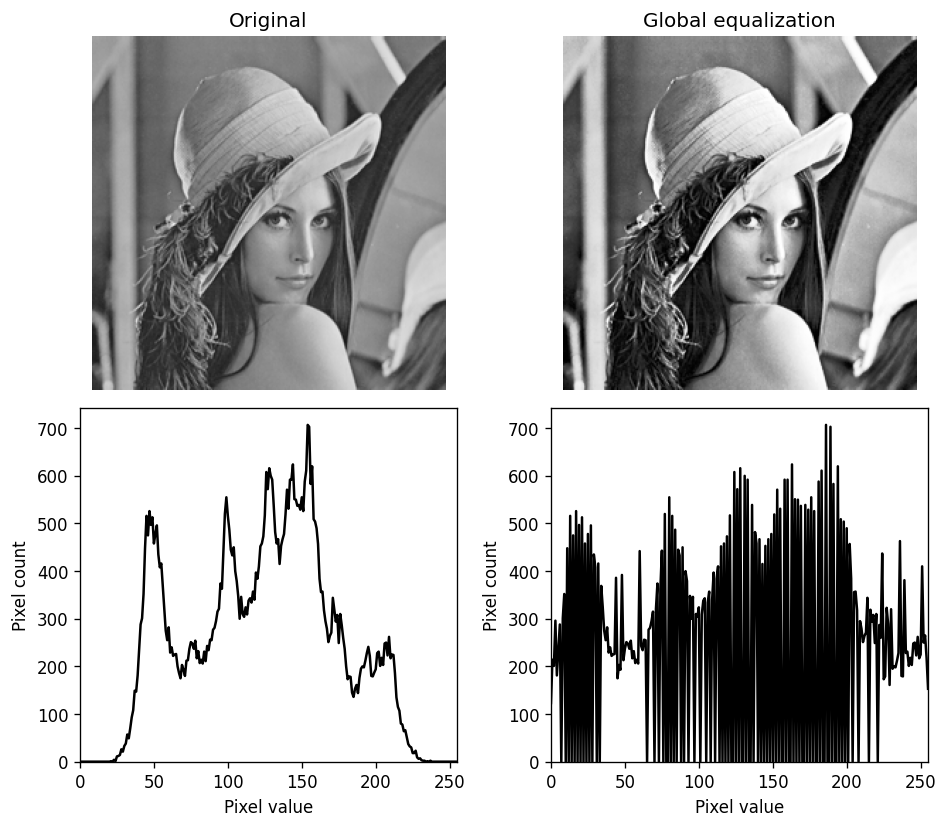

In [5]:
# 셀 5: 전체 히스토그램 평활화
# 영상 전체의 누적 분포를 이용하여 밝기 값을 다시 배정한다.

# equalizeHist는 8비트 단일 채널 영상에 전체 히스토그램 평활화를 적용한다.
equalized = cv2.equalizeHist(gray)

# 모든 영상은 0~255, 히스토그램은 공통 y축 범위로 표시하여 비교한다.
def compare_gray(arrays, titles):
    fig, axes = plt.subplots(2, len(arrays), figsize=(4*len(arrays), 7), squeeze=False)
    ymax = max(hist(a).max() for a in arrays)*1.05
    for i, (a,title) in enumerate(zip(arrays,titles)):
        axes[0,i].imshow(a, cmap='gray', vmin=0, vmax=255)
        axes[0,i].set_title(title)
        axes[0,i].axis('off')
        axes[1,i].plot(hist(a), color='black')
        axes[1,i].set(xlim=(0,255), ylim=(0,ymax), xlabel='Pixel value', ylabel='Pixel count')
        print(f'{title}: min={a.min()}, max={a.max()}, mean={a.mean():.3f}, std={a.std():.3f}')
    fig.tight_layout()
    plt.show()

compare_gray([gray,equalized], ['Original','Global equalization'])
constant = np.full((16,16),128,dtype=np.uint8)
assert np.array_equal(constant,cv2.equalizeHist(constant))

### 차이를 쉽게 보는 교육용 입력

아래 그림의 입력은 원본 Gray를 의도적으로 좁은 밝기 범위로 변환한 것이다. 원본 사진 자체의 상태로 오해하지 않는다.

$$
I_{\mathrm{low}}=\operatorname{round}(80+0.4I)
$$





> [!note] 왜 히스토그램이 완전히 평평하지 않을까?
> 정수 밝기와 한정된 픽셀 개수 때문에 모든 bin의 개수가 같아지는 것은 아니다. 같은 입력 밝기는 같은 출력 밝기로 옮겨지므로 빈 구간이나 봉우리가 남을 수 있다. 손실된 원래 세부 정보를 복구하는 작업도 아니다.



- 아래에서 입력과 출력의 CDF, 입력 밝기를 출력 밝기로 바꾸는 변환표를 함께 비교한다.
- 표준편차는 밝기 분포의 퍼짐을 나타내며 영상 품질 점수는 아니다.

Synthetic low contrast: min=88, max=175, mean=129.423, std=19.051
Global equalization: min=0, max=255, mean=129.602, std=73.579
수식 구현과 OpenCV의 최대 차이: 0


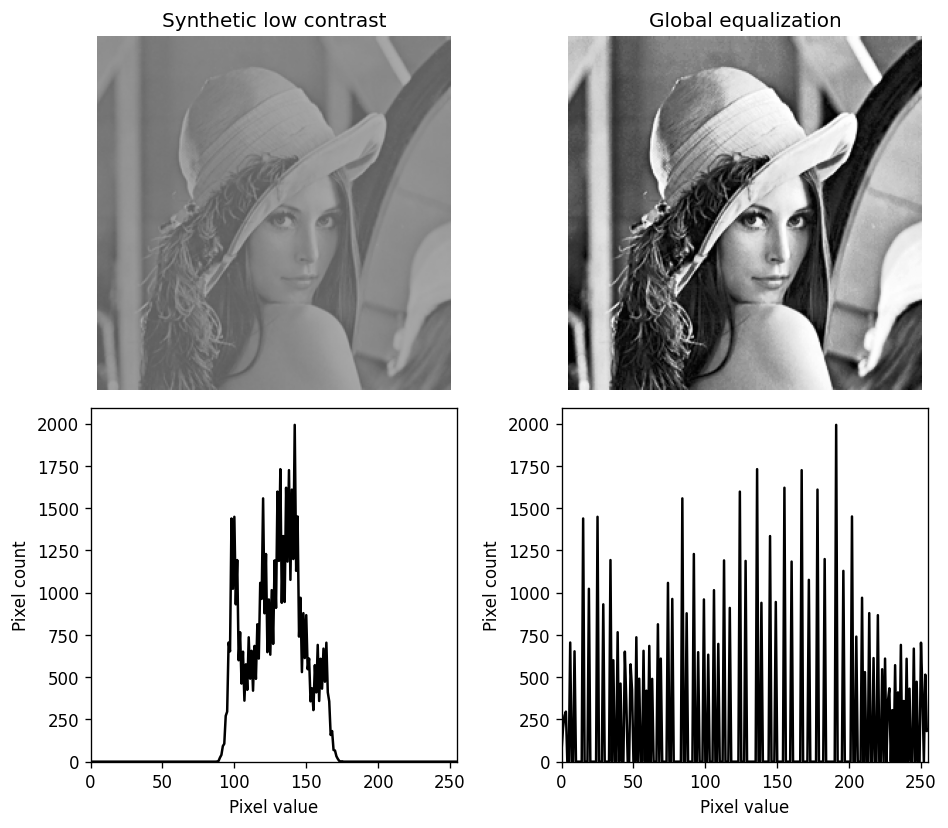

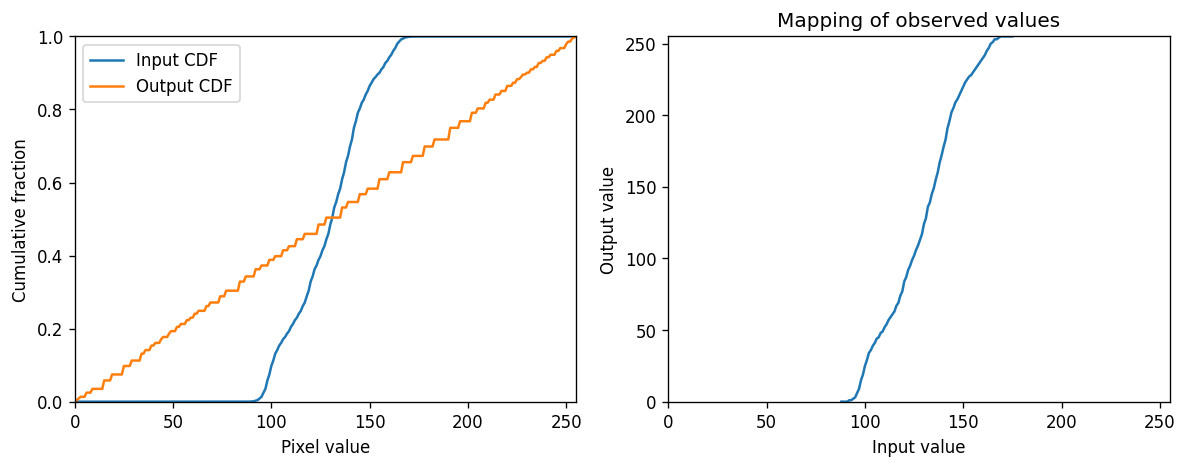

In [6]:
# 셀 6: 저대비 입력과 CDF 변환표
# 밝기 범위를 인위적으로 줄인 입력에서 직접 만든 변환표와 OpenCV 결과를 비교한다.

# 원본과 구분되는 교육용 저대비 영상을 만들어 변환 효과를 쉽게 비교한다.
low = np.round(80 + 0.4*gray.astype(np.float64)).astype(np.uint8)
low_eq = cv2.equalizeHist(low)
compare_gray([low,low_eq], ['Synthetic low contrast','Global equalization'])
p = hist(low)/low.size
# 밝기별 비율을 누적하여 해당 밝기 이하 픽셀의 비율 CDF를 구한다.
cdf = np.cumsum(p)
# 입력에 실제로 등장하는 가장 낮은 밝기의 누적 비율을 찾는다.
cmin = cdf[np.flatnonzero(p)[0]]
# 최초의 유효 CDF를 빼고 0~255로 재배정한다. 단색 입력은 분모가 0이므로 별도 처리가 필요하다.
lut = np.round(255*(cdf-cmin)/(1-cmin)).clip(0,255).astype(np.uint8)
# 각 입력 밝기를 변환표의 인덱스로 사용하여 전체 영상의 새 밝기를 얻는다.
manual = lut[low]
print('수식 구현과 OpenCV의 최대 차이:', int(np.abs(manual.astype(np.int16)-low_eq.astype(np.int16)).max()))
fig, axes = plt.subplots(1,2,figsize=(10,4))
axes[0].plot(cdf,label='Input CDF')
axes[0].plot(np.cumsum(hist(low_eq))/low_eq.size,label='Output CDF')
axes[0].set(xlim=(0,255),ylim=(0,1),xlabel='Pixel value',ylabel='Cumulative fraction')
axes[0].legend()
present = np.flatnonzero(p)
axes[1].plot(present,lut[present])
axes[1].set(xlim=(0,255),ylim=(0,255),xlabel='Input value',ylabel='Output value',title='Mapping of observed values')
fig.tight_layout()
plt.show()

## 2.4 적응형 히스토그램 평활화 (CLAHE)

### 전체 대신 작은 영역을 기준으로 조절하기

- 전체 영상에 한 변환표를 쓰면 어두운 부분과 밝은 부분을 모두 적절히 조정하기 어려울 수 있다.
- AHE는 작은 영역별 분포를 사용하지만, 작은 잡음도 크게 강조할 수 있다.
- CLAHE는 **Contrast Limited Adaptive Histogram Equalization**, 즉 대비 제한 적응형 히스토그램 평활화다.
- 작은 영역의 히스토그램에서 지나치게 높은 bin의 개수를 제한하고 초과분을 재분배한다.
- 영역별 변환을 보간하여 경계가 갑자기 갈라져 보이는 현상을 줄인다.
- 잡음 강조를 제한하지만 잡음을 제거하는 필터는 아니다.



| 설정 | 의미 | 바꿀 때 관찰할 점 |
| :---: | :---: | :---: |
| `clipLimit=2.0` | 대비 제한 조절값 | 큰 양수는 일반적으로 더 강한 대비 변화를 허용하지만 잡음도 강조될 수 있음 |
| `tileGridSize=(8, 8)` | 가로·세로 영역의 개수 | 개수를 늘리면 각 영역이 작아져 더 국소적인 변화를 반영 |

> [!warning] 자주 헷갈리는 설정
> `(8, 8)`은 **8×8픽셀짜리 영역**이라는 뜻이 아니다. 가로 8개, 세로 8개 영역으로 나눈다는 뜻이다. `clipLimit=2.0`도 픽셀 밝기를 2로 제한하거나 bin마다 픽셀 2개만 남긴다는 뜻이 아니다. 내부적으로 영역 크기와 bin 수에 맞춰 제한값을 계산한다.

### 전체 평활화와 CLAHE 비교

| 구분 | 전체 평활화 | CLAHE |
| :---: | :---: | :---: |
| 참조 범위 | 영상 전체 | 작은 영역별 |
| 같은 입력 밝기 | 같은 출력 밝기 | 위치에 따라 다른 출력 가능 |
| 주요 설정 | 별도 대비 제한값 없음 | clipLimit, tileGridSize |
| 주의점 | 일부 영역의 과도한 변화 | 잡음·질감의 과도한 강조 가능 |

Original: min=21, max=237, mean=123.550, std=47.624
Global equalization: min=0, max=255, mean=128.318, std=73.624
CLAHE: min=6, max=254, mean=132.530, std=58.365
Synthetic low contrast: min=88, max=175, mean=129.423, std=19.051
Global equalization: min=0, max=255, mean=129.602, std=73.579
CLAHE: min=47, max=216, mean=134.502, std=36.162


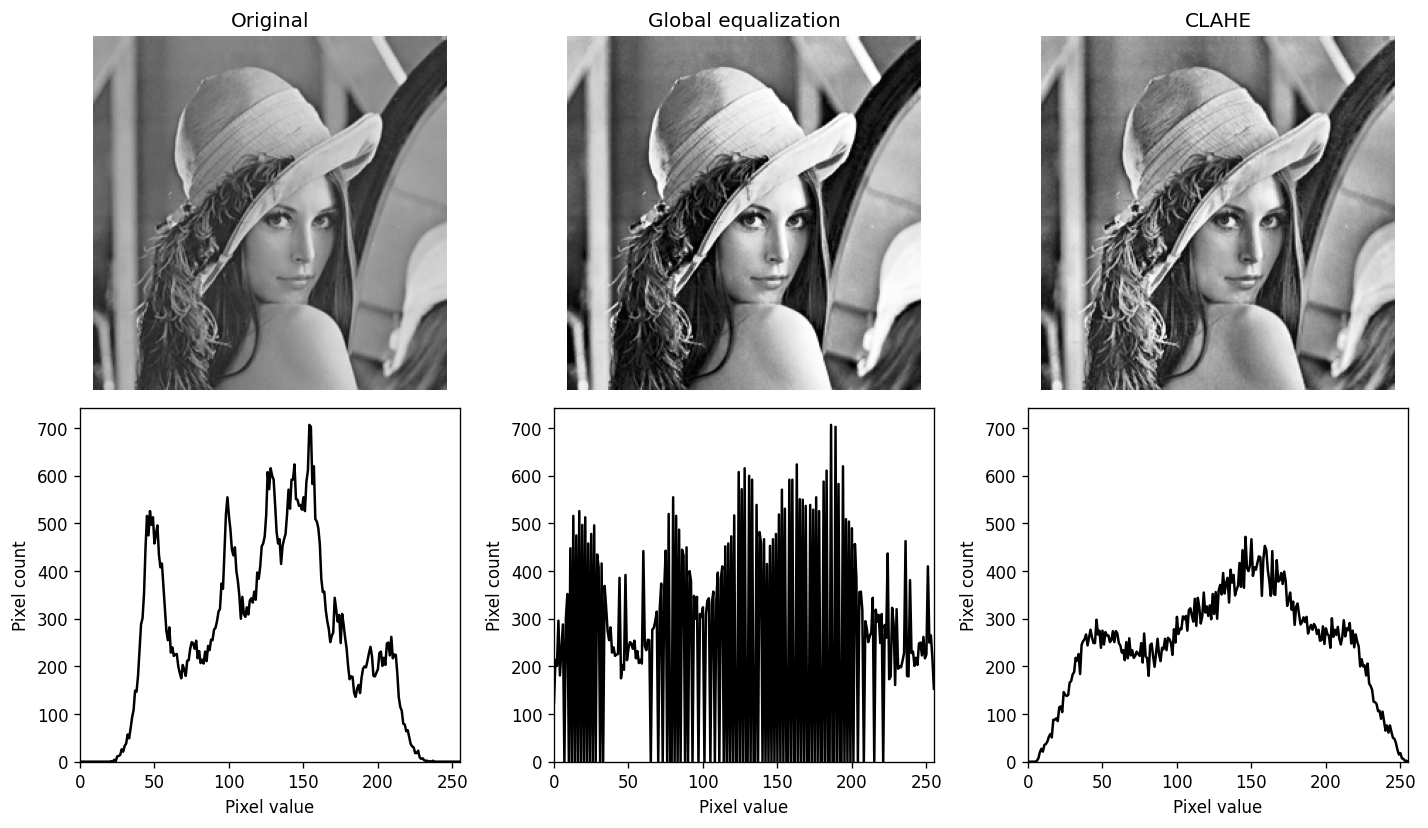

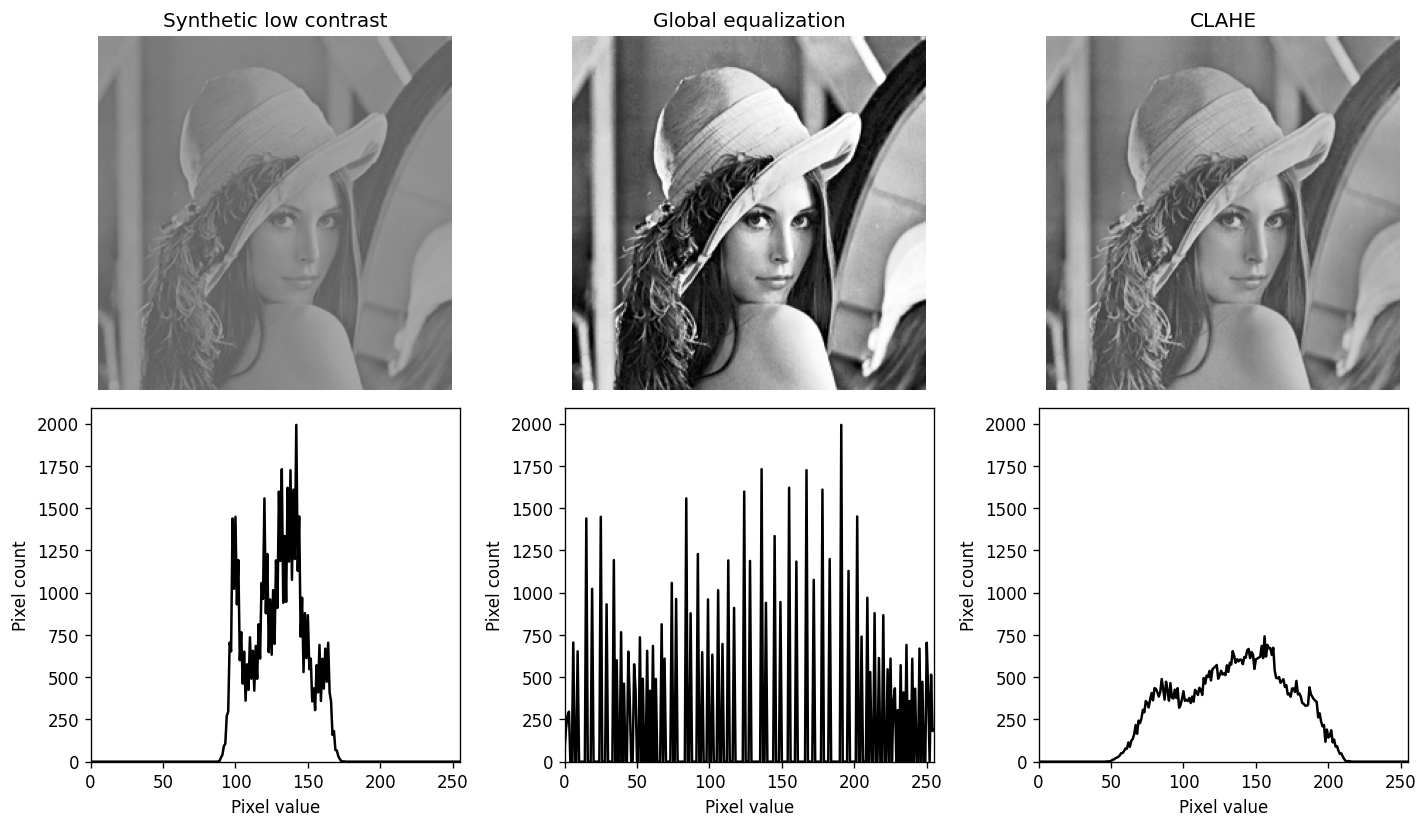

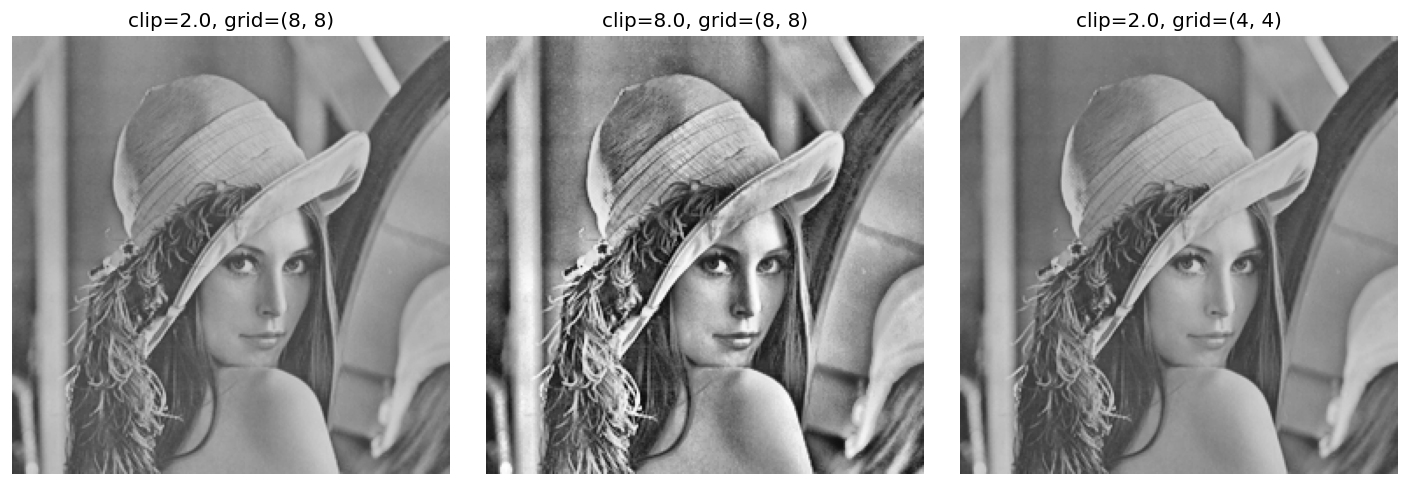

In [7]:
# 셀 7: CLAHE와 설정 비교
# 영역별 대비를 조절하며, clipLimit과 영역 개수의 영향을 따로 살펴본다.

# clipLimit은 대비 제한값, tileGridSize는 픽셀 크기가 아니라 가로·세로 타일 개수다.
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
cl = clahe.apply(gray)
low_cl = clahe.apply(low)
compare_gray([gray,equalized,cl], ['Original','Global equalization','CLAHE'])
compare_gray([low,low_eq,low_cl], ['Synthetic low contrast','Global equalization','CLAHE'])
# 한 번에 한 설정만 바꾸어 효과를 비교한다.
settings = [(2.0,(8,8)), (8.0,(8,8)), (2.0,(4,4))]
fig, axes = plt.subplots(1,3,figsize=(12,4))
for ax, (limit,grid) in zip(axes,settings):
    result = cv2.createCLAHE(clipLimit=limit,tileGridSize=grid).apply(low)
    ax.imshow(result,cmap='gray',vmin=0,vmax=255)
    ax.set_title(f'clip={limit}, grid={grid}')
    ax.axis('off')
fig.tight_layout()
plt.show()

### 결과 해석

- 교육용 저대비 입력은 **88~175**에 모여 있었다. 전체 평활화 후에는 **0~255**, CLAHE 후에는 **47~216** 범위가 되었다.
- 전체 평활화는 밝기 범위를 크게 넓혔지만, 히스토그램에는 빈 구간과 높은 봉우리가 남는다.
- 이 설정의 CLAHE는 전체 평활화보다 범위를 덜 넓히면서 국소 대비를 바꿨다. 다른 입력과 설정에서도 항상 같은 순서가 되는 것은 아니다.
- 머리카락과 얼굴의 세부 표현뿐 아니라 배경 질감이 과하게 강조되는지도 함께 비교한다.

### 컬러 영상에는 밝기 성분만 적용하기





- B·G·R을 각각 평활화하면 세 성분의 상대적인 관계가 달라져 색이 변할 수 있다.
- Y만 처리하면 색차 성분을 유지하면서 밝기 성분을 조정할 수 있다.
- 다만 BGR 복원 과정의 반올림·범위 제한 때문에 색이 완전히 보존된다고 보장하지는 않는다.

Y 처리 중 Cr, Cb 유지: True


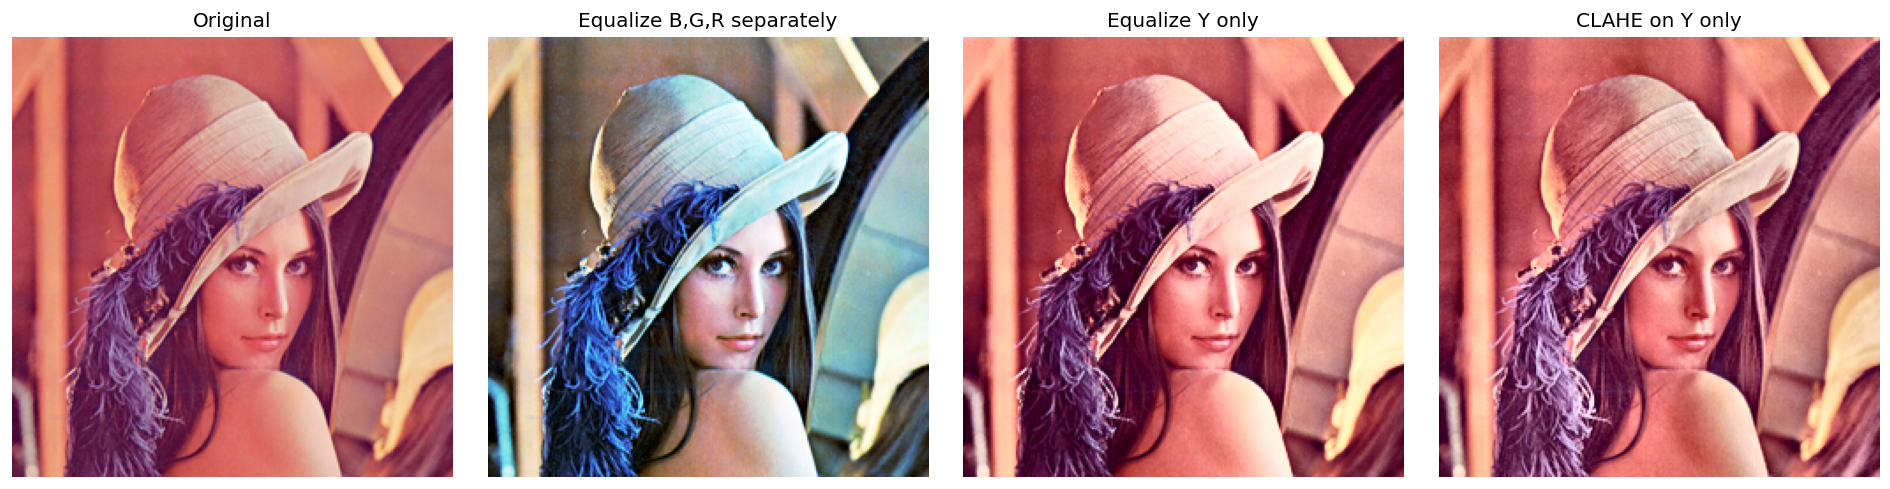

In [8]:
# 셀 8: 컬러 영상의 밝기 성분만 조절
# Y만 처리하고 Cr·Cb를 유지한 뒤 BGR로 되돌려 채널별 평활화와 비교한다.

# 밝기 성분 Y와 색차 성분 Cr·Cb를 분리할 수 있는 표현으로 변환한다.
ycrcb = cv2.cvtColor(img,cv2.COLOR_BGR2YCrCb)
# OpenCV의 반환 순서는 Y, Cr, Cb이다. 각 채널은 높이×너비 배열이다.
Y, Cr, Cb = cv2.split(ycrcb)
y_eq = cv2.merge([cv2.equalizeHist(Y),Cr,Cb])
y_cl = cv2.merge([clahe.apply(Y),Cr,Cb])
assert np.array_equal(y_cl[:,:,1:],ycrcb[:,:,1:])
color_eq = cv2.cvtColor(y_eq,cv2.COLOR_YCrCb2BGR)
color_cl = cv2.cvtColor(y_cl,cv2.COLOR_YCrCb2BGR)
# 비교용: 세 채널을 독립적으로 바꾸면 색 관계가 달라질 수 있다.
channel_eq = cv2.merge([cv2.equalizeHist(c) for c in cv2.split(img)])
fig, axes = plt.subplots(1,4,figsize=(16,4))
for ax,a,title in zip(axes,[img,channel_eq,color_eq,color_cl],
                      ['Original','Equalize B,G,R separately','Equalize Y only','CLAHE on Y only']):
    ax.imshow(cv2.cvtColor(a,cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')
fig.tight_layout()
plt.show()
print('Y 처리 중 Cr, Cb 유지:', np.array_equal(y_cl[:,:,1:],ycrcb[:,:,1:]))

## 참고 문서

- [OpenCV — Histograms: Find, Plot, Analyze](https://docs.opencv.org/4.x/d1/db7/tutorial_py_histogram_begins.html)
- [OpenCV — Histogram Equalization](https://docs.opencv.org/4.x/d5/daf/tutorial_py_histogram_equalization.html)
- [OpenCV — CLAHE API](https://docs.opencv.org/4.x/d6/db6/classcv_1_1CLAHE.html)

## 실행 검증

OpenCV 5.0.0에서 8개 코드 셀을 같은 Python 실행 상태로 순차 실행하여 출력과 그림을 기록했다. 앞선 실행에서 확인한 Jupyter 커널 통신 권한 제한으로, 이번 검증은 Python 순차 실행으로 진행했다. Jupyter 전체 실행 자체는 검증하지 않았다.